### **Task 1. Imports and data loading**

Start by importing packages needed to build machine learning models to achieve the goal of this project.

In [25]:
# Import packages for data munipulation
import pandas as pd
import numpy as np

# Import packages for data visulization
import matplotlib.pyplot as plt
import seaborn as sns

# Import packages for data preprocessing
from sklearn.feature_extraction.text import CountVectorizer

# Import packages for data modeling
from sklearn.model_selection import train_test_split 
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score,\
classification_report, confusion_matrix, ConfusionMatrixDisplay

from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from xgboost import plot_importance

Load the data from the provided csv file into a dataframe.

In [26]:
data = pd.read_csv(r"D:\Data_analytics\google_certificate_project\course5\end_project\ML_Tiktok\tiktok_dataset.csv")

### **Task 2: Examine data, summary info, and descriptive stats**

Get an overall views of data set

In [27]:
# Display first few rows
data.head(5)

,#,claim_status,video_id,video_duration_sec,video_transcription_text,verified_status,author_ban_status,video_view_count,video_like_count,video_share_count,video_download_count,video_comment_count
0,1,claim,7017666017,59,someone shared with me that drone deliveries a...,not verified,under review,343296.0,19425.0,241.0,1.0,0.0
1,2,claim,4014381136,32,someone shared with me that there are more mic...,not verified,active,140877.0,77355.0,19034.0,1161.0,684.0
2,3,claim,9859838091,31,someone shared with me that american industria...,not verified,active,902185.0,97690.0,2858.0,833.0,329.0
3,4,claim,1866847991,25,someone shared with me that the metro of st. p...,not verified,active,437506.0,239954.0,34812.0,1234.0,584.0
4,5,claim,7105231098,19,someone shared with me that the number of busi...,not verified,active,56167.0,34987.0,4110.0,547.0,152.0


In [28]:
# Get the number of rows and columns
data.shape

(19382, 12)

In [29]:
# Get data type of columns
data.dtypes

#                             int64
claim_status                 object
video_id                      int64
video_duration_sec            int64
video_transcription_text     object
verified_status              object
author_ban_status            object
video_view_count            float64
video_like_count            float64
video_share_count           float64
video_download_count        float64
video_comment_count         float64
dtype: object

In [30]:
# Get basic information
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19382 entries, 0 to 19381
Data columns (total 12 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   #                         19382 non-null  int64  
 1   claim_status              19084 non-null  object 
 2   video_id                  19382 non-null  int64  
 3   video_duration_sec        19382 non-null  int64  
 4   video_transcription_text  19084 non-null  object 
 5   verified_status           19382 non-null  object 
 6   author_ban_status         19382 non-null  object 
 7   video_view_count          19084 non-null  float64
 8   video_like_count          19084 non-null  float64
 9   video_share_count         19084 non-null  float64
 10  video_download_count      19084 non-null  float64
 11  video_comment_count       19084 non-null  float64
dtypes: float64(5), int64(3), object(4)
memory usage: 1.8+ MB


In [31]:
# Generate basic statistical information
data.describe(include = 'all')

,#,claim_status,video_id,video_duration_sec,video_transcription_text,verified_status,author_ban_status,video_view_count,video_like_count,video_share_count,video_download_count,video_comment_count
count,19382.000000,19084,1.938200e+04,19382.000000,19084,19382,19382,19084.000000,19084.000000,19084.000000,19084.000000,19084.000000
unique,NaN,2,NaN,NaN,19012,2,3,NaN,NaN,NaN,NaN,NaN
top,NaN,claim,NaN,NaN,a friend read in the media a claim that badmi...,not verified,active,NaN,NaN,NaN,NaN,NaN
freq,NaN,9608,NaN,NaN,2,18142,15663,NaN,NaN,NaN,NaN,NaN
mean,9691.500000,NaN,5.627454e+09,32.421732,NaN,NaN,NaN,254708.558688,84304.636030,16735.248323,1049.429627,349.312146
std,5595.245794,NaN,2.536440e+09,16.229967,NaN,NaN,NaN,322893.280814,133420.546814,32036.174350,2004.299894,799.638865
min,1.000000,NaN,1.234959e+09,5.000000,NaN,NaN,NaN,20.000000,0.000000,0.000000,0.000000,0.000000
25%,4846.250000,NaN,3.430417e+09,18.000000,NaN,NaN,NaN,4942.500000,810.750000,115.000000,7.000000,1.000000
50%,9691.500000,NaN,5.618664e+09,32.000000,NaN,NaN,NaN,9954.500000,3403.500000,717.000000,46.000000,9.000000
75%,14536.750000,NaN,7.843960e+09,47.000000,NaN,NaN,NaN,504327.000000,125020.000000,18222.000000,1156.250000,292.000000


As we found above, there are some missing values and numerous outliers within the dataset. Therefore, the next step is to **identify them and clean the data**.

Check missing values, duplicated values,outliers and class balance of the data set

In [32]:
# check for missing values
data.isna().sum()

#                             0
claim_status                298
video_id                      0
video_duration_sec            0
video_transcription_text    298
verified_status               0
author_ban_status             0
video_view_count            298
video_like_count            298
video_share_count           298
video_download_count        298
video_comment_count         298
dtype: int64

In [33]:
# Drop rows with missing value
data_dropped = data.dropna()

# Display first few rows after handling missing values
data_dropped.isna().sum()

#                           0
claim_status                0
video_id                    0
video_duration_sec          0
video_transcription_text    0
verified_status             0
author_ban_status           0
video_view_count            0
video_like_count            0
video_share_count           0
video_download_count        0
video_comment_count         0
dtype: int64

In [34]:
# Check for duplicate
data_dropped.duplicated().sum()

np.int64(0)

Because the tree-based models are robost to outliers, we dont need 
to check and handle its

In [35]:
# Check for class balance
data_dropped['claim_status'].value_counts(normalize = True)

claim_status
claim      0.503458
opinion    0.496542
Name: proportion, dtype: float64

To sum up, as we can see, the missing values are removed and there are not duplicated values and the model didn't require to handle outliers. Based on our class balance check, the ratio of **'claim'** to **'opinion'** is 5 to 5

### **Task 3: Feature engineering**

For all variables, The column, video_transcription_text, is hard to used for model. Therefore, we need to transform it from object type into numerical type.

In [36]:
# Extract the length of each `video_transcription_text` and add this as a column to the dataframe
data_dropped['text_length'] = data_dropped['video_transcription_text'].str.len()
data_dropped.head(5)

C:\Users\zby45\AppData\Local\Temp\ipykernel_51436\4159895624.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data_dropped['text_length'] = data_dropped['video_transcription_text'].str.len()


,#,claim_status,video_id,video_duration_sec,video_transcription_text,verified_status,author_ban_status,video_view_count,video_like_count,video_share_count,video_download_count,video_comment_count,text_length
0,1,claim,7017666017,59,someone shared with me that drone deliveries a...,not verified,under review,343296.0,19425.0,241.0,1.0,0.0,97
1,2,claim,4014381136,32,someone shared with me that there are more mic...,not verified,active,140877.0,77355.0,19034.0,1161.0,684.0,107
2,3,claim,9859838091,31,someone shared with me that american industria...,not verified,active,902185.0,97690.0,2858.0,833.0,329.0,137
3,4,claim,1866847991,25,someone shared with me that the metro of st. p...,not verified,active,437506.0,239954.0,34812.0,1234.0,584.0,131
4,5,claim,7105231098,19,someone shared with me that the number of busi...,not verified,active,56167.0,34987.0,4110.0,547.0,152.0,128


In [37]:
# Calculate the average text_length for claim and opinion 
data_dropped.groupby(by = 'claim_status')['text_length'].mean()

claim_status
claim      95.376978
opinion    82.722562
Name: text_length, dtype: float64

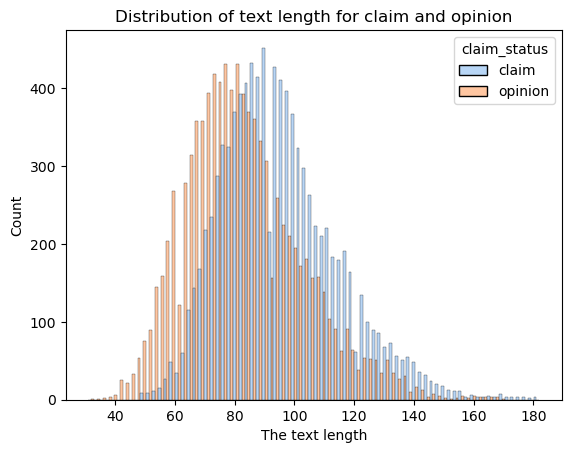

In [38]:
# Create two histgram in one plot
sns.histplot(data=data_dropped, x='text_length', hue='claim_status',
            stat='count', multiple='dodge', kde=False, 
            palette='pastel', element='bars', legend=True)
plt.xlabel('The text length')
plt.ylabel('Count')
plt.title('Distribution of text length for claim and opinion')
plt.show()

**Feature selection and feature transformation**  
Since columns, video id and video transcription text, are unuseless variables for pridiction, its should be remove from data set. Remaining categorical variables require to transform to numerical variables with get dummies function

In [39]:
# Create feature matrix as X and Drop unecessary data
X = data_dropped.drop(columns = ['claim_status','#','video_id','video_transcription_text'])

# Dummy encode remaining categorical columns
X = pd.get_dummies(X,columns = ['verified_status','author_ban_status'],drop_first = True)

# Create target variable and encode it
y = data_dropped['claim_status'].replace({'claim':1,'opinion':0})

X.head(5)


C:\Users\zby45\AppData\Local\Temp\ipykernel_51436\1146753023.py:8: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  y = data_dropped['claim_status'].replace({'claim':1,'opinion':0})


,video_duration_sec,video_view_count,video_like_count,video_share_count,video_download_count,video_comment_count,text_length,verified_status_verified,author_ban_status_banned,author_ban_status_under review
0,59,343296.0,19425.0,241.0,1.0,0.0,97,False,False,True
1,32,140877.0,77355.0,19034.0,1161.0,684.0,107,False,False,False
2,31,902185.0,97690.0,2858.0,833.0,329.0,137,False,False,False
3,25,437506.0,239954.0,34812.0,1234.0,584.0,131,False,False,False
4,19,56167.0,34987.0,4110.0,547.0,152.0,128,False,False,False


To further improve the efficiency of feature engineering, data professionals can create new features. For example, we can calculate `video_like_count` **divided by** `video_duration_sec` to capture the relationship between like count and video duration.  
  
For this task, the complex feature engineering is not required due to a few number of features

### **Task 4: Split the data into train/validation/test set**  
Our goal is to split the dataset into train, validation and test sets with a 60/20/20 split.

In [40]:
# Split data into train and test set
X_train,X_test,y_train,y_test = train_test_split(X, y, test_size = 0.2, random_state = 42)

# Split train data into subtrain set and validation set
X_tr,X_val,y_tr,y_val = train_test_split(X_train, y_train, test_size = 0.25, random_state = 42)

In [41]:
# Get shape of each training, validation, and testing set
X_tr.shape,X_val.shape,X_test.shape,y_tr.shape,y_val.shape,y_test.shape

((11450, 10), (3817, 10), (3817, 10), (11450,), (3817,), (3817,))

### **Task 5. Build models**  
For this tasks, I decided to build random forest and XGBoost model and compare both scores to determine which one is champion model

**Build a random forest model**  
Fit a random forest model to the training set. Use cross-validation to tune the hyperparameters and select the model that performs best on recall.

In [42]:
# Instantiate random forest model
rf = RandomForestClassifier(random_state = 42)

# Create a dictonary of hyperparameters to tune
rf_params = {'max_depth':[5,7,None],
             'max_features':[0.3,0.6],
             'max_samples':[0.7],
             'min_samples_split':[2,3],
             'min_samples_leaf':[1,2],
             'n_estimators':[75,100,200]}

# Define a list of scoring metrics to capture
rf_scoring = ['f1','precision','recall','accuracy']

# Instantiate GridSearch object
rf_cv = GridSearchCV(estimator = rf,
                     param_grid = rf_params, 
                     scoring = rf_scoring, 
                     cv = 5,
                     refit = 'recall',
                     n_jobs = -1,
                     verbose = 2)

In [43]:
%%time
# Fit the model to data
rf_cv.fit(X_tr,y_tr)

Fitting 5 folds for each of 72 candidates, totalling 360 fits
CPU times: total: 2.39 s
Wall time: 35.6 s


,estimator,RandomForestC...ndom_state=42)
,param_grid,"{'max_depth': [5, 7, ...], 'max_features': [0.3, 0.6], 'max_samples': [0.7], 'min_samples_leaf': [1, 2], ...}"
,scoring,"['f1', 'precision', ...]"
,n_jobs,-1
,refit,'recall'
,cv,5
,verbose,2
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,n_estimators,100


In [72]:
# Save the result to the local disk
import pickle

path = r"D:\Data_analytics\google_certificate_project\course5\end_project\ML_Tiktok\Instantiated_model"
with open(path + r'\rf_grid_cv.pkl', 'wb') as w:
    pickle.dump(rf_cv,w)

with open(path + r'\rf_grid_cv.pkl', 'rb') as r:
    rf_cv_2 = pickle.load(r)


In [45]:
# Get the best score
rf_cv_2.best_score_

np.float64(0.9913766326500252)

In [46]:
# Get the best parameters
rf_cv_2.best_estimator_

,n_estimators,100
,criterion,'gini'
,max_depth,5
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,0.6
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [47]:
# Access the GridSearch results and convert it to a pandas df
rf_cv_2_df = pd.DataFrame(rf_cv_2.cv_results_)

# Examine the GridSearch results df at column `mean_test_precision` in the best index
rf_cv_2_df['mean_test_precision'][rf_cv_2.best_index_]

np.float64(1.0)

This precision score is too high for a model. So, I suspect that the model is overfitted by subtrain data. But I have to take more exam to confirm my hypothesis.

**Build an XGBoost model**

In [48]:
# Instantiate the XGBoost model
xgb = XGBClassifier(objective = 'binary:logistic',random_state = 42,)

# Create dictionary of hyperparameters
xgb_params = {'max_depth':[4,8,12],
              'n_estimators':[300,500],
              'learning_rate':[0.01,0.05,0.1],
              'min_child_weight':[3,5]}

# Create list of scoring
xgb_scoring = ['f1','precision','recall','accuracy']

# Instantiate the GridSearchCV object
xgb_cv = GridSearchCV(estimator = xgb,
                      param_grid = xgb_params,
                      cv = 5,
                      scoring = xgb_scoring,
                      refit = 'recall',
                      n_jobs = -1,
                      verbose = 2)

In [53]:
%%time
# Fit the xgb model with sub train set
xgb_cv.fit(X_tr,y_tr)

Fitting 5 folds for each of 36 candidates, totalling 180 fits
CPU times: total: 13.2 s
Wall time: 10.8 s


,estimator,"XGBClassifier...ree=None, ...)"
,param_grid,"{'learning_rate': [0.01, 0.05, ...], 'max_depth': [4, 8, ...], 'min_child_weight': [3, 5], 'n_estimators': [300, 500]}"
,scoring,"['f1', 'precision', ...]"
,n_jobs,-1
,refit,'recall'
,cv,5
,verbose,2
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,objective,'binary:logistic'


In [70]:
path = r"D:\Data_analytics\google_certificate_project\course5\end_project\ML_Tiktok\Instantiated_model"
with open(path + r'\xgb_grid_cv.pkl', 'wb') as w:
    pickle.dump(xgb_cv,w)

with open(path + r'\xgb_grid_cv.pkl', 'rb') as r:
    xgb_cv_2 = pickle.load(r)



In [55]:
# Get the best score
xgb_cv_2.best_score_

np.float64(0.9898246109904496)

In [56]:
# Get the best parameters
xgb_cv_2.best_params_

{'learning_rate': 0.1,
 'max_depth': 4,
 'min_child_weight': 3,
 'n_estimators': 500}

In [57]:
# Access the GridSearchCV and convert into dataframe df
xgb_cv_2_df = pd.DataFrame(xgb_cv_2.cv_results_)

# Examine the GridSearch results df at column `mean_test_precision` in the best index
xgb_cv_2_df['mean_test_precision'][xgb_cv_2.best_index_]

np.float64(0.9982625164280094)

### **Task 6. Evaluate model**

Evaluate models against validation criteria.

**Random forest model**

In [58]:
# Use the random forest model with best estimators to predict y on validation set
y_pre1 = rf_cv_2.best_estimator_.predict(X_val)

# Display the prediction on the validation set
y_pre1

array([1, 0, 0, ..., 0, 0, 1], shape=(3817,))

In [59]:
# Display the true label of validation set
y_val

1871     1
16574    0
17741    0
17214    0
17821    0
        ..
15929    0
12177    0
18295    0
17339    0
9186     1
Name: claim_status, Length: 3817, dtype: int64

In [60]:
# Define a helpful function confusion_matrix to visulize the result of our model
def plot_confusion_matrix(y_true,y_pre,model_object):
    cm = confusion_matrix(y_true,y_pre, labels = model_object.classes_)
    disp = ConfusionMatrixDisplay(cm, display_labels = model_object.classes_)
    ax = disp.plot()
    return ax


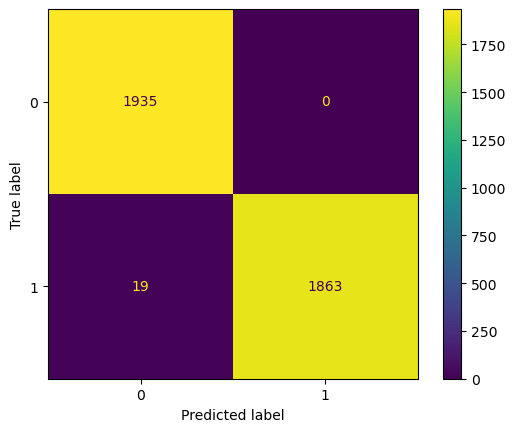

In [61]:
# Visulize the result of random forest model
plot_confusion_matrix(y_val,y_pre1,rf_cv_2)

For this confusion matrix of random forest model, we can see the FN and FP is too few, 19 and 0 respectively. Based on this plot, we can infer the score of f1, precision and recall is very high. Therefore, the next step is to gain each score in a table

In [62]:
# Create a classification report for randon forest model
target_labels = ['opinion','claim']
print(classification_report(y_val, y_pre1, target_names = target_labels))

              precision    recall  f1-score   support

     opinion       0.99      1.00      1.00      1935
       claim       1.00      0.99      0.99      1882

    accuracy                           1.00      3817
   macro avg       1.00      0.99      1.00      3817
weighted avg       1.00      1.00      1.00      3817



As we suppose before, the score of big four metrics all is high. According to this finding, we can think that the random forest model is great for the data set.   
  
For the precision of opinion, this means 99% of samples predicted as opinion by the model are true opinions among all predicted values.   
  
For the recall of opinion, this means almost 100% of samples predicted as opinon by the model are true among all actual values.
  
For the f1 score, when both score of precision and recall, the f1 score will be high.  
  
For accuraccy score, this means almost 100% of samples predicted as true by models are true among all values

**XGBoost model**

In [63]:
# Use the XGBoost model with best estimators to predict y on validation set
y_pre2 = xgb_cv_2.best_estimator_.predict(X_val)

# Display the prediction on the validation set
y_pre2

array([1, 0, 0, ..., 0, 0, 1], shape=(3817,))

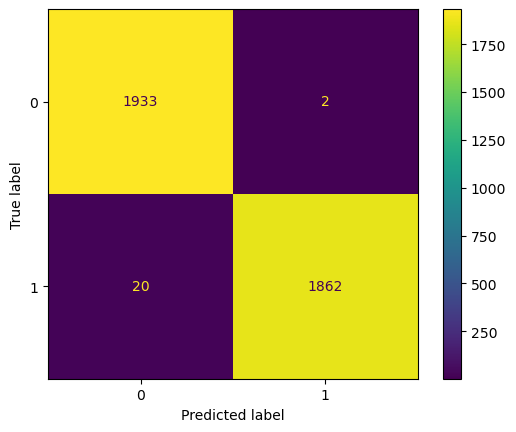

In [64]:
# Use the function defined before to visulize the confusion matrix
plot_confusion_matrix(y_val, y_pre2, xgb_cv_2)

In [65]:
print(classification_report(y_val, y_pre2, target_names = target_labels))

              precision    recall  f1-score   support

     opinion       0.99      1.00      0.99      1935
       claim       1.00      0.99      0.99      1882

    accuracy                           0.99      3817
   macro avg       0.99      0.99      0.99      3817
weighted avg       0.99      0.99      0.99      3817



For this reports, we can find the result of XGBoost model is similar to the result pf random forest model, but the socre of XGBoost in accuracy is less than the socre of random forest model. Therefore, I decided to select random forest model as my champion model

In [66]:
# Select ranfom forest model as my final model and predict on test set
y_pre_final = rf_cv_2.best_estimator_.predict(X_test)

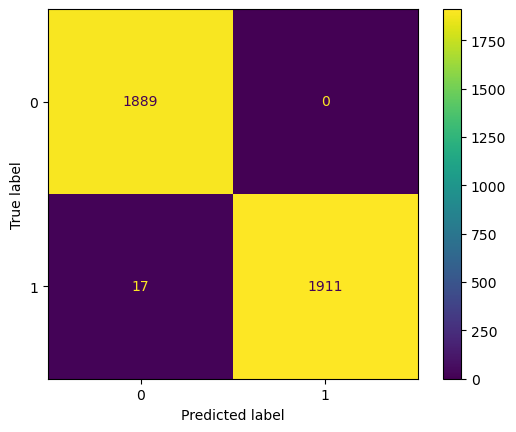

In [67]:
# Visulize the confusion matrix of random forest on test set
plot_confusion_matrix(y_test, y_pre_final, rf_cv_2)

In [73]:
# Get the each score on test data
print(classification_report(y_test, y_pre_final, target_names = target_labels))

              precision    recall  f1-score   support

     opinion       0.99      1.00      1.00      1889
       claim       1.00      0.99      1.00      1928

    accuracy                           1.00      3817
   macro avg       1.00      1.00      1.00      3817
weighted avg       1.00      1.00      1.00      3817



Wow! the result is amazing. In the same number of samples between validation set and test set, The random forest model on test set overperform that on validation set. There are high score on f1, precision, recall, and accuracy

**Feature importance**

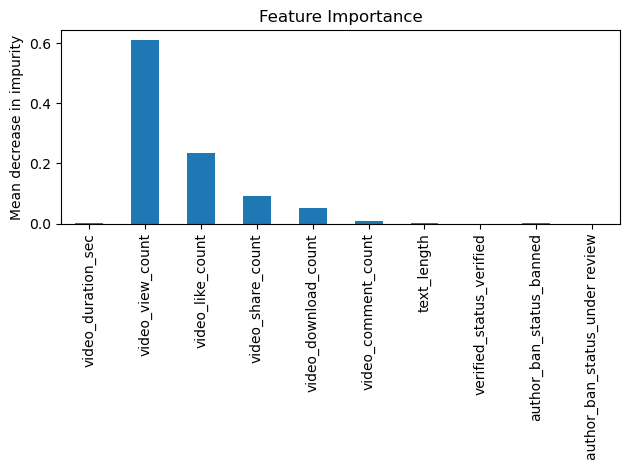

In [68]:
# Convert feature importance form array into series
importance = rf_cv_2.best_estimator_.feature_importances_
rf_importance = pd.Series(importance, index = X_test.columns)

# Visulize the feature importance
fig, ax = plt.subplots()
rf_importance.plot.bar(ax = ax)
ax.set_title("Feature Importance")
ax.set_ylabel("Mean decrease in impurity")
fig.tight_layout()

### **Conclusion**

**Key takeways:**
- Performing EDA for the data set, I found there are a great number of outliers in key feature importance of the data set. Therefore, I choose the random forest model and XGBoost model that are not affected by outlier to predict future data
- Feature engineering, as my experience, I delete some uselessful features, such as ID, # etc. And then I transform the categorical variables into numerical variables. But for this data set, there are a few features that dont require further feature extraction.
- Building model, I split the data set into 3 parts, train data set (60%), validation set (20%) and test set (20%) respectively. Based on the training set, I train the random forest model and XGBoost model and utilise the validation set to select champion model. The campion model is random forest. Eventually, test set is used for testing the final performance of RF model
- Feature importance, I obtain the Feature importance at the end of this task. The result is that `video_view_count`, `video_like_count`, `video_share_count`, `video_comment_count` are the four most important features in the data. This result of feature importance means that we can pay more attention to these features and try improve the efficiency of model according to these features

**Business explanation**
- For the final model, accuracy, recall, precision and F1 are all close to 100%, which means the model can predict almost all samples correctly. Therefore, this model is suitable for final deployment. In other words, the business team can use it to predict the risk posts, especially for some **claim** video directly.
- From our feature importance results, the business team or project managers can consider more on four most important features than other features in the model. The concentration on these features can save numerous labour resource in overseeing the video quality obviously

**Limitation**
- For the final results, since the random forest model and XGBoost model is black-box model, the result expanation requires more powerful tools, such as PDP and SHAP value, to further explain the final results.
- For the data set, this data set is synthetic educational purpose data set from Coursera platform. Hence, it lack of actual noisy from real business enviornment and enough number of features from real world. But if the model is deployed into real online platform, the efficiency may will be decrease significantly